In [1]:
import pickle
import os

import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from dataset.dataset import load_data
from dataset.utils import *
import matplotlib.pyplot as plt

from models.model import *

torch.set_printoptions(sci_mode=False)

import lrp
from models.lrp_converter import convert

from PIL import Image

In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print("Device:", device, torch.cuda.get_device_name(0))
else:
    print("Device:", device)

Device: cuda:0 NVIDIA GeForce GTX 1650 Ti


In [3]:
# single playing card dataset has 17 concepts
# multi card dataset has 52 concepts


N_CONCEPT = 17
N_CLASSES = 52
val_loader = load_data("./dataset/playing_cards/val.pkl", 16, dataset_root="./dataset/playing_cards", has_class=False, return_orig=True)

concept_index_to_string = IndexToString("./dataset/playing_cards/attributes.txt")


"""
N_CONCEPT = 52
N_CLASSES = 1
val_loader = load_data("./dataset/multi_playing_cards/val.pkl", 16, dataset_root="./dataset/multi_playing_cards", has_class=False, return_orig=True)
"""

concept_index_to_string = IndexToString("./dataset/multi_playing_cards/concepts_test.txt")

XtoC = PlayingCardNet(num_classes=N_CONCEPT)
XtoC.load_state_dict(torch.load("./saves/single_XtoC_converted.pth"))
#XtoC.load_state_dict(torch.load("./saves/multi_no_freeze_XtoC_converted.pth"))
XtoC.to(device)
XtoC.eval()

print("model loaded")

model loaded


In [4]:
##### https://github.com/fhvilshoj/TorchLRP/blob/74253a1be05f0be0b7c535736023408670443b6e/examples/visualization.py#L60
def heatmap(X, cmap_name="seismic"):
	cmap = plt.cm.get_cmap(cmap_name)

	if X.shape[1] in [1, 3]:  # move channel index to end + convert to np array
		X = X.permute(0, 2, 3, 1).detach().cpu().numpy()
	if isinstance(X, torch.Tensor):  # convert tensor to np array
		X = X.detach().cpu().numpy()

	shape = X.shape
	tmp = X.sum(axis=-1) # Reduce channel axis

	tmp = project(tmp, output_range=(0, 255)).astype(int)
	tmp = cmap(tmp.flatten())[:, :3].T
	tmp = tmp.T

	shape = list(shape)
	shape[-1] = 3
	return tmp.reshape(shape).astype(np.float32)


def project(X, output_range=(0, 1)):
	absmax = np.abs(X).max(axis=tuple(range(1, len(X.shape))), keepdims=True)
	X /= absmax + (absmax == 0).astype(float)
	X = (X+1) / 2. # range [0, 1]
	X = output_range[0] + X * (output_range[1] - output_range[0]) # range [x, y]
	return X

In [5]:
XtoC = convert(XtoC).to(device)

print(XtoC)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1))
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
  (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
  (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (12): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
  (13): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (14): ReLU()
  (15): AdaptiveAvgPool2d(output_size=(7, 7))
  (16): Flatten(start_dim=1, end_dim=-1)
  (17): Dropou

## Show true concepts and classification + predicted concepts and classification

True image size (channels, width, height): torch.Size([3, 274, 174])
True  image concepts: tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 1., 0.])


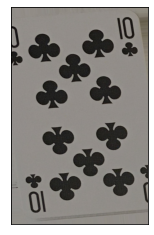

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


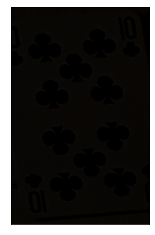

In [10]:
imageId = 100

images, labels, concepts, original_imgs = next(iter(val_loader))
image, label = images[imageId].to(device), labels[imageId].to(device)

# print / show input
print("True image size (channels, width, height):", image.size())
print("True  image concepts:", concepts[imageId])

plt.xticks([])
plt.yticks([])
plt.imshow(original_imgs[imageId].squeeze().permute(1, 2, 0))
plt.show()

plt.xticks([])
plt.yticks([])
plt.imshow(images[imageId].squeeze().permute(1, 2, 0))
plt.show()

In [44]:
image, label = images[imageId].to(device), labels[imageId].to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None

# get model prediction and LRP map for classification
prediction = XtoC(image)

pred_concepts_readable = torch.nn.Sigmoid()(prediction)
print("Predicted concepts:", pred_concepts_readable)

# print concept as string if prediction is >= 0.5
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        print(f"id: {idx},", f"concept name: {concept_index_to_string(idx)},", f"sig value: {i.item()}")

Predicted concepts: tensor([[    0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0000,     1.0000,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0000,     1.0000,     0.0000]],
       device='cuda:0', grad_fn=<SigmoidBackward0>)
id: 9, concept name: 3D, sig value: 1.0
id: 15, concept name: 4S, sig value: 0.9999998807907104


## Generate LRP saliency maps for concepts using a single rule

10C


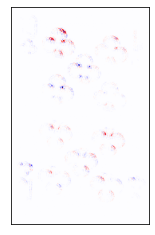

10D


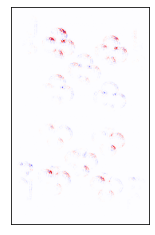

10H


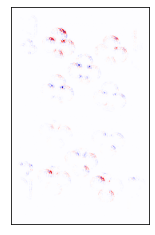

10S


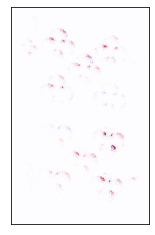

2C


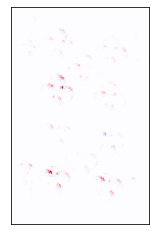

2D


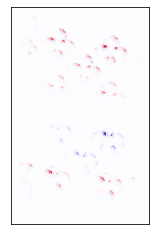

2H


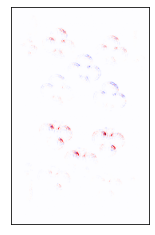

2S


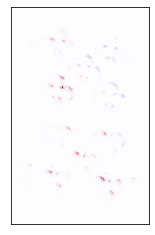

3C


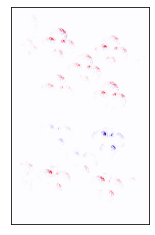

3D


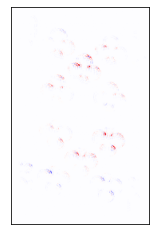

3H


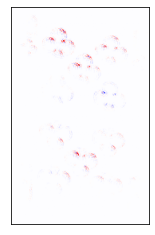

3S


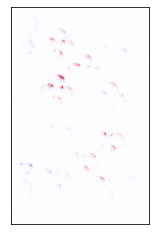

4C


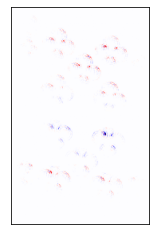

4D


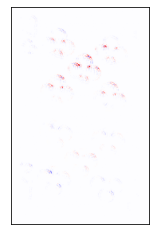

4H


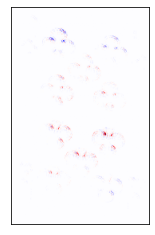

4S


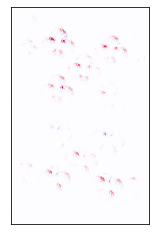

5C


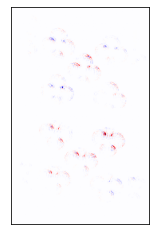

In [45]:
image, label = images[imageId].to(device), labels[imageId].to(device)
#image, label = images.to(device), labels.to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None  # Reset gradient

#pred_concepts = XtoC.forward(image, explain=True, rule="alpha1beta0")
pred_concepts = XtoC.forward(image, explain=True, rule="alpha2beta1")
#pred_concepts = XtoC.forward(image, explain=True, rule="epsilon")
#pred_concepts = XtoC.forward(image, explain=True, rule="gradient")

# get saliecy maps for each concept
for i in range(pred_concepts.size(1)):
    filter_out = torch.zeros_like(pred_concepts)
    filter_out[:,i] += 1

    # Get the gradient of each input
    image_gradient = torch.autograd.grad(
        pred_concepts,
        image,
        grad_outputs=filter_out,
        retain_graph=True)[0]


    attr = heatmap(image_gradient, cmap_name='seismic')
    
    print(concept_index_to_string(i))

    plt.xticks([])
    plt.yticks([])
    #plt.title(label=concept_index_to_string(i), fontsize=15)
    plt.imshow(attr.squeeze(), cmap='seismic')
    #plt.savefig(f'temp/{i}.png')
    plt.show()

    plt.close()

## Generate LRP saliency maps for concepts using composite rules

In [31]:
XtoC_model_1 = []
XtoC_model_2 = []
XtoC_model_3 = []

for idx, m in enumerate(XtoC.children()):
    if idx < 8:
        XtoC_model_1.append(m)
    elif idx < 15:
        XtoC_model_2.append(m)
    else:
        XtoC_model_3.append(m)

XtoC_model_1 = lrp.Sequential(*XtoC_model_1)
XtoC_model_2 = lrp.Sequential(*XtoC_model_2)
XtoC_model_3 = lrp.Sequential(*XtoC_model_3)

XtoC_model_1.to(device)
XtoC_model_2.to(device)
XtoC_model_3.to(device)

print(XtoC_model_1)
print(XtoC_model_2)
print(XtoC_model_3)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1))
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
  (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
Sequential(
  (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
  (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
  (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
)
Sequential(
  (0): AdaptiveAvgPool2d(output_size=(7, 7))
  (1): Flatten(start_dim=1, end_d

10C


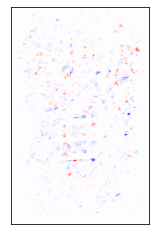

10D


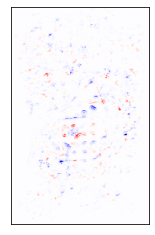

10H


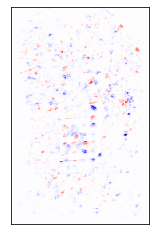

10S


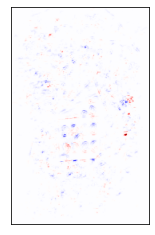

2C


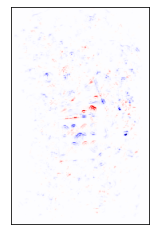

2D


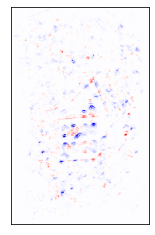

2H


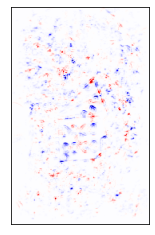

2S


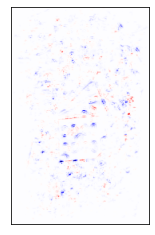

3C


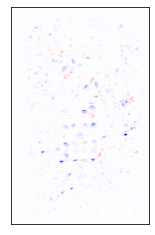

3D


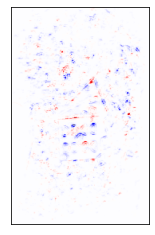

3H


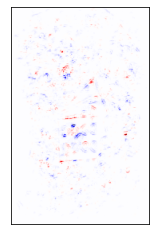

3S


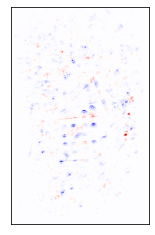

4C


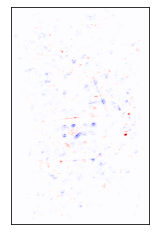

4D


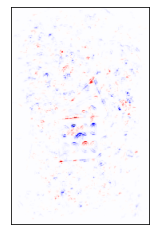

4H


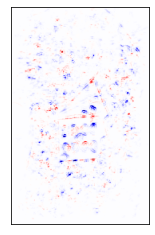

4S


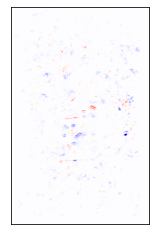

5C


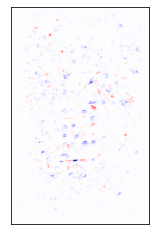

5D


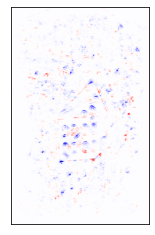

5H


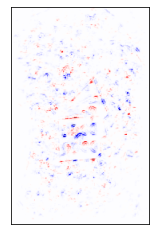

5S


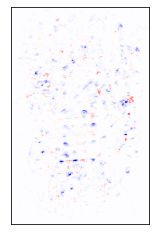

6C


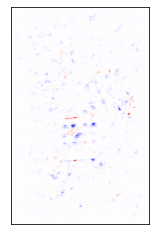

6D


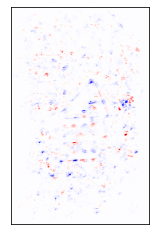

6H


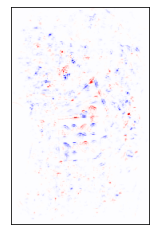

6S


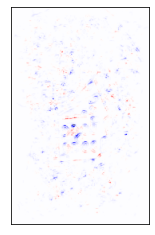

7C


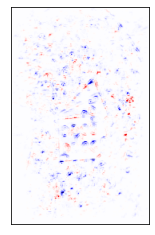

7D


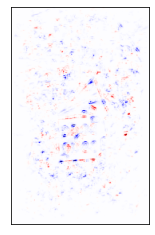

7H


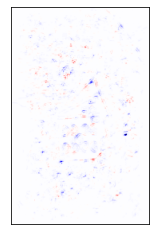

7S


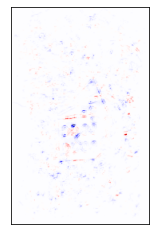

8C


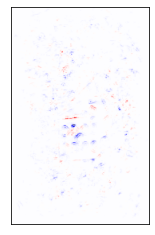

8D


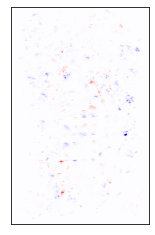

8H


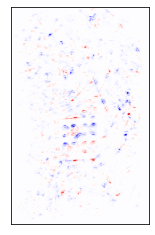

8S


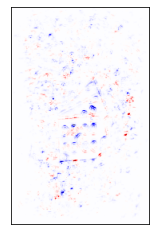

9C


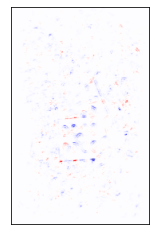

9D


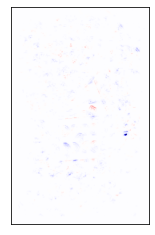

9H


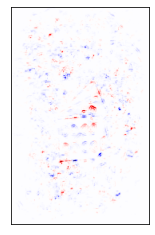

9S


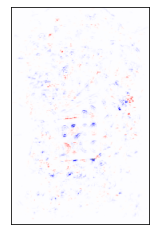

AC


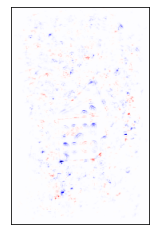

AD


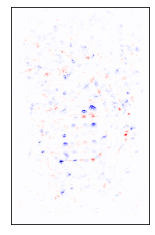

AH


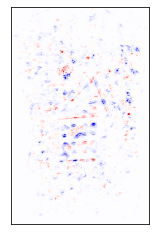

AS


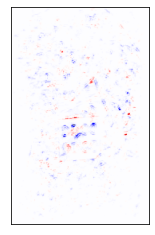

JC


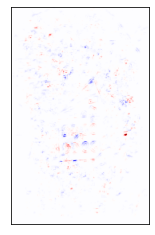

JD


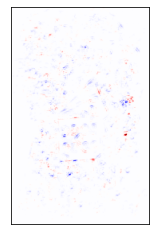

JH


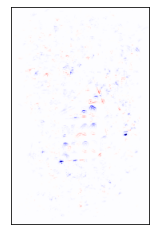

JS


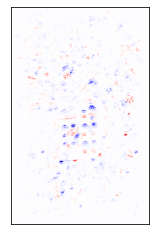

KC


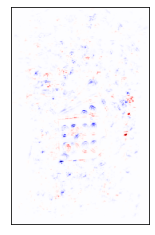

KD


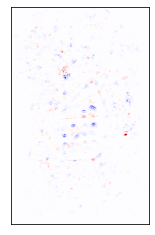

KH


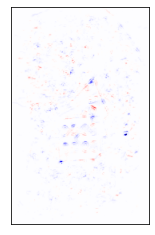

KS


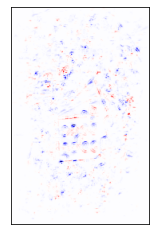

QC


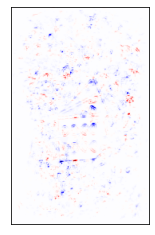

QD


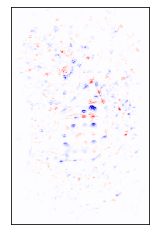

QH


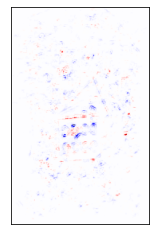

QS


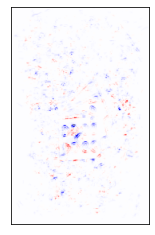

In [38]:
image, label = images[imageId].to(device), labels[imageId].to(device)
#image, label = images.to(device), labels.to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None  # Reset gradient

output_1 = XtoC_model_1.forward(image, explain=True, rule="alpha1beta0")
output_2 = XtoC_model_2.forward(output_1, explain=True, rule="epsilon")
pred_concepts = XtoC_model_3.forward(output_2, explain=True, rule="gradient")

"""
# get saliecy maps for a subset of concept (first 15)
for i in range(15):
    filter_out = torch.zeros_like(pred_concepts)
    filter_out[:,i] += 1

    # Get the gradient of each input
    image_gradient = torch.autograd.grad(
        pred_concepts,
        image,
        grad_outputs=filter_out,
        retain_graph=True)[0]


    attr = heatmap(image_gradient, cmap_name='seismic')
    
    print(concept_index_to_string(i))

    plt.xticks([])
    plt.yticks([])
    #plt.title(label=concept_index_to_string(i), fontsize=15)
    plt.imshow(attr.squeeze(), cmap='seismic')
    #plt.savefig(f'temp/{i}.png')
    plt.show()

    plt.close()
"""
    
    
# get saliecy maps for top 5 concepts
pred_precent_concepts = []
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        pred_precent_concepts.append((idx, i.item()))

pred_precent_concepts = sorted(pred_precent_concepts, key=lambda x: -x[1])

for i in range(pred_concepts.size(1)):
    filter_out = torch.zeros_like(pred_concepts)
    filter_out[:,i] += 1

    # Get the gradient of each input
    image_gradient = torch.autograd.grad(
        pred_concepts,
        image,
        grad_outputs=filter_out,
        retain_graph=True)[0]


    attr = heatmap(image_gradient, cmap_name='seismic')
    
    print(concept_index_to_string(i))

    plt.xticks([])
    plt.yticks([])
    #plt.title(label=concept_index_to_string(i), fontsize=15)
    plt.imshow(attr.squeeze(), cmap='seismic')
    #plt.savefig(f'temp/{i[0]}.png')
    plt.show()

    plt.close() 


## Average concept saliency maps

Saliency maps are grouped together by name and then averaged.

In [24]:
concept_groups = [
        ("bill_shape", (1, 4)),
        ("wing_color", (5, 10)),
        ("upperparts_color", (11, 23)),
        ("breast_pattern", (24, 25)),
        ("back_color", (26, 31)),
        ("tail_shape", (32, 32)),
        ("upper_tail_color", (33, 37)),
        ("head_pattern", (38, 39)),
        ("breast_color", (40, 45)),
        ("throat_color", (46, 50)),
        ("eye_color", (51, 52)),
        ("bill_length", (53, 54)),
        ("forehead_color", (55, 59)),
        ("under_tail_color", (60, 64)),
        ("nape_color", (65, 70)),
        ("belly_color", (71, 77)),
        ("wing_shape", (78, 78)),
        ("size", (79, 81)),
        ("shape", (82, 84)),
        ("back_pattern", (85, 87)),
        ("tail_pattern", (88, 90)),
        ("primary_color", (91, 96)),
        ("leg_color", (97, 99)),
        ("bill_color", (100, 103)),
        ("crown_color", (104, 109)),
        ("wing_pattern", (110, 112))
]

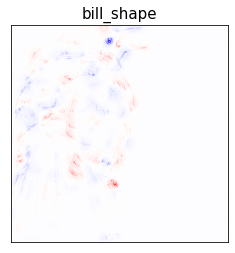

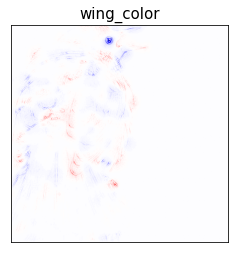

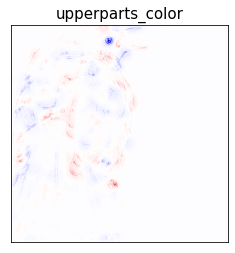

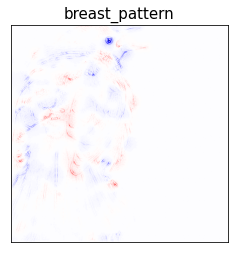

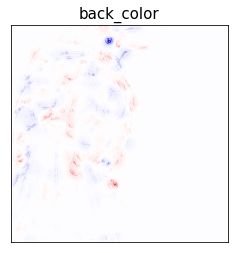

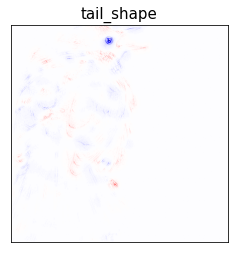

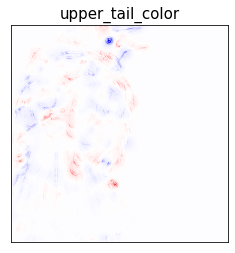

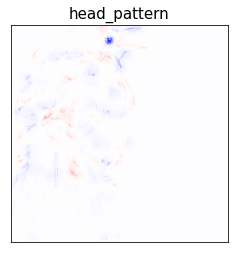

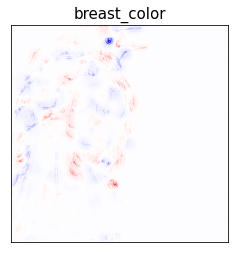

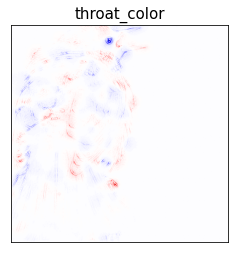

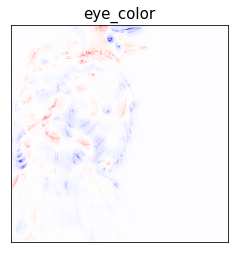

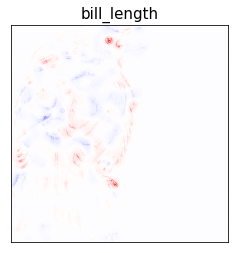

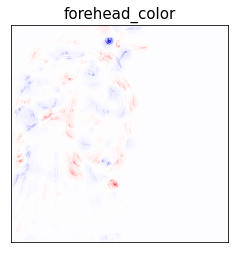

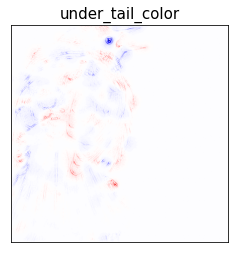

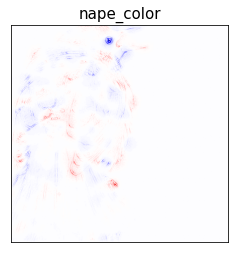

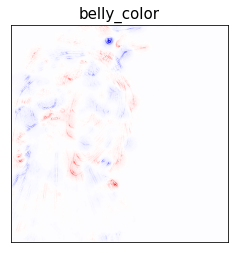

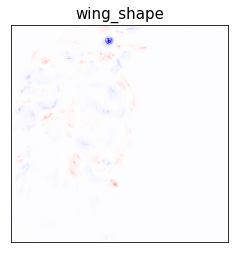

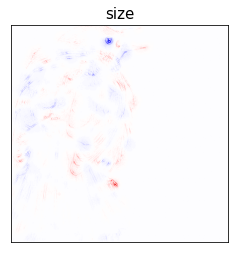

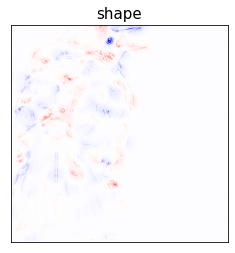

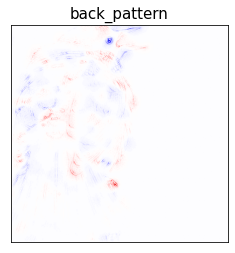

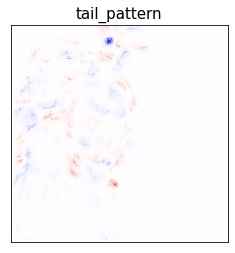

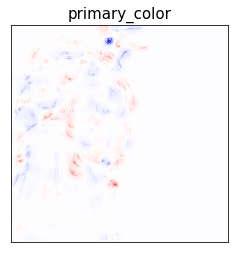

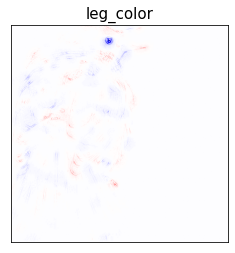

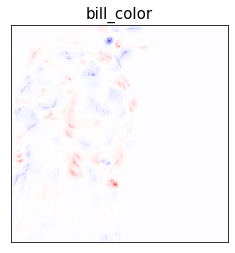

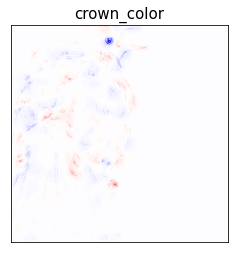

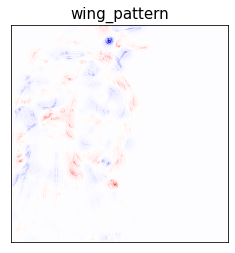

In [26]:
for group in concept_groups:
    image, label = images[imageId].to(device), labels[imageId].to(device)
    #image, label = images.to(device), labels.to(device)
    image = image.unsqueeze(0)
    image.requires_grad_(True)
    image.grad = None  # Reset gradient

    output_1 = XtoC_model_1.forward(image, explain=True, rule="alpha1beta0")
    output_2 = XtoC_model_2.forward(output_1, explain=True, rule="epsilon")
    pred_concepts = XtoC_model_3.forward(output_2, explain=True, rule="gradient")
    
    group_grads = []

    # get saliecy maps for each concept group
    for i in range(group[1][0] - 1, group[1][1]):  # start id -> end id (is's start from 0)
        filter_out = torch.zeros_like(pred_concepts)
        filter_out[:,i] += 1

        # Get the gradient of each input
        image_gradient = torch.autograd.grad(
            pred_concepts,
            image,
            grad_outputs=filter_out,
            retain_graph=True)[0]
        
        group_grads.append(image_gradient)
        
    avg_attr = heatmap(torch.stack(group_grads).mean((0)), cmap_name='seismic')

    plt.xticks([])
    plt.yticks([])
    plt.title(label=group[0], fontsize=15)
    plt.imshow(avg_attr.squeeze(), cmap='seismic')
    #plt.savefig(f'temp/{group[0]}.png')
    plt.show()

    plt.close()